# ***Python DA Assignment 2 - Data Visualization***

Data visualization helps transform raw data into
meaningful insights by representing it graphically.
* Libraries:
Python offers powerful libraries like Matplotlib (low-level,
customizable) and Seaborn (high-level, aesthetically
pleasing, built on Matplotlib).

## **1) Loading the Taxis Dataset**

In [24]:
import seaborn as sns
df = sns.load_dataset("taxis")

* Seaborn contains sample datasets.
* sns.load_dataset("taxis") loads the taxi trip dataset into a DataFrame.

In [25]:
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

* head() displays the first 5 records.

In [26]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

df.info() shows
* Number of rows and columns
* Column names
* Non-null (non-missing) values count
* Data type of each column
* Memory usage

# **2) Handling Missing Values**

In [41]:

# Check for missing values in the dataset and identify columns with missing data.
print("missing values : ")
print(df.isnull().sum())

missing values : 
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


* isnull() identifies missing values.
* sum() counts missing values in each column.

In [28]:
# Numerical columns - fill with median
import pandas as pd

numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns - fill with mode
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
   df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Imputation:\n")
print(df.isnull().sum())


Missing Values After Imputation:

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


* Numerical columns (fare, tip, distance, etc.) are filled using the median ( less affected by extreme values (outliers)).
* Categorical columns (payment, pickup_borough, etc.) are filled using the mode( the most frequently occurring value).
* After filling the missing values, isnull().sum() is used again to confirm that the missing values have been handled.

In [29]:
# For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.
df.dropna(inplace=True)

print("\nShape after removing remaining missing values: ")
print(df.shape)



Shape after removing remaining missing values: 
(6341, 14)


# **3) Visualizations using Matplotlib/Pandas Plot:**

Matplotlib is the foundational plotting library in Python. It
provides fine-grained control over plots.

In [30]:
import matplotlib.pyplot as plt
import pandas as pd


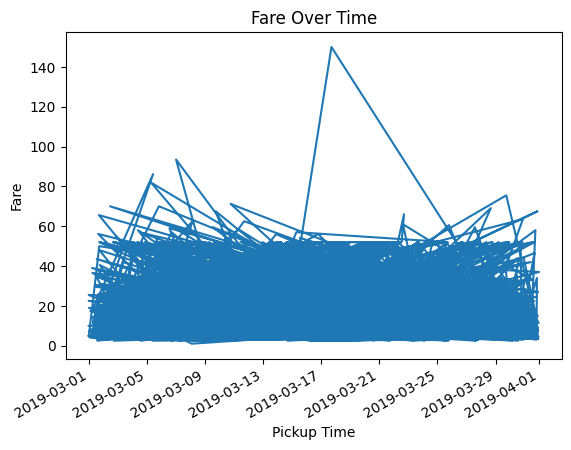

In [31]:
# Line Chart Plot
# a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis.
# Ensure the pickup column is converted to a datetime format before plotting.
if 'pickup' in df.columns:
    df['pickup'] = pd.to_datetime(df['pickup'])
    df.set_index('pickup', inplace=True)

df['fare'].plot(kind='line')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.title('Fare Over Time')
plt.show()

Line Chart: Trends with confidence intervals.
* Converts pickup column to datetime.
* X-axis → pickup timestamp.
* Y-axis → fare amount.
* Shows fare changes over time.

Text(0.5, 1.0, 'Total Fare by Pickup Borough')

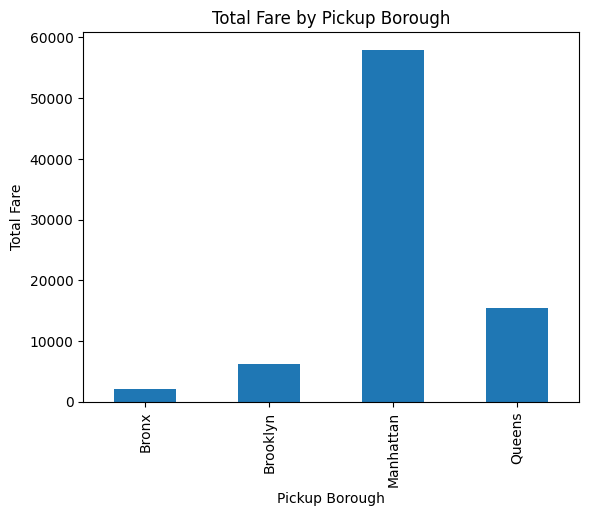

In [32]:
# Bar Chart
# Create a bar chart to show the total fare for each pickup_borough.
# Group the data by pickup_borough and sum the fare for each group.
grouped_data = df.groupby('pickup_borough')['fare'].sum()

# Create a bar chart
grouped_data.plot(kind='bar')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.title('Total Fare by Pickup Borough')


Bar Chart: Compare categories with statistical aggregation.
* groupby() groups records by borough.
* sum() calculates total fare.
* Bar chart compares borough revenues.

Text(0.5, 1.0, 'Distribution of Trips by Payment Method')

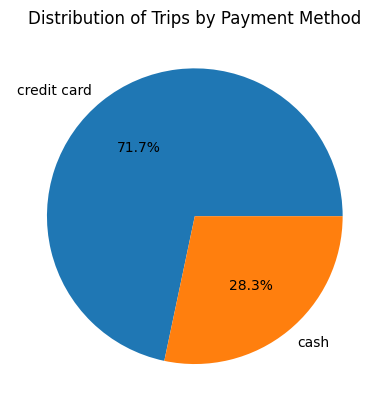

In [33]:
# Pie Chart
# Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.).
# Each slice should represent the count of trips for a specific payment method.
payment_method_counts = df['payment'].value_counts()

# Create a pie chart
plt.pie(payment_method_counts, labels=payment_method_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Trips by Payment Method')


Pie chart : Show proportions.
* Counts trips by payment method.
* Pie slices show percentage distribution.

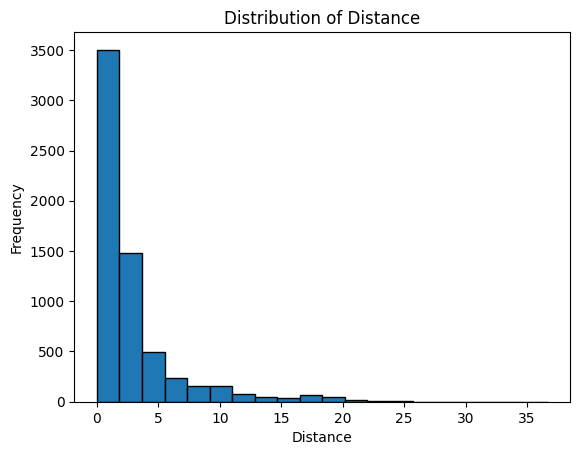

In [34]:
# Histogram
# Create a histogram to visualize the distribution of distance.
# Customize the number of bins for better granularity and ensure the plot is easy to interpret.
plt.hist(df['distance'], bins=20, edgecolor='black')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.title('Distribution of Distance')
plt.show()

Histogram : Show distribution of data.
* bins=20 improves detail -A histogram divides the data into intervals called bins and counts how many values fall into each interval.

Text(0.5, 1.0, 'Distribution of Tip Amounts by Pickup Borough')

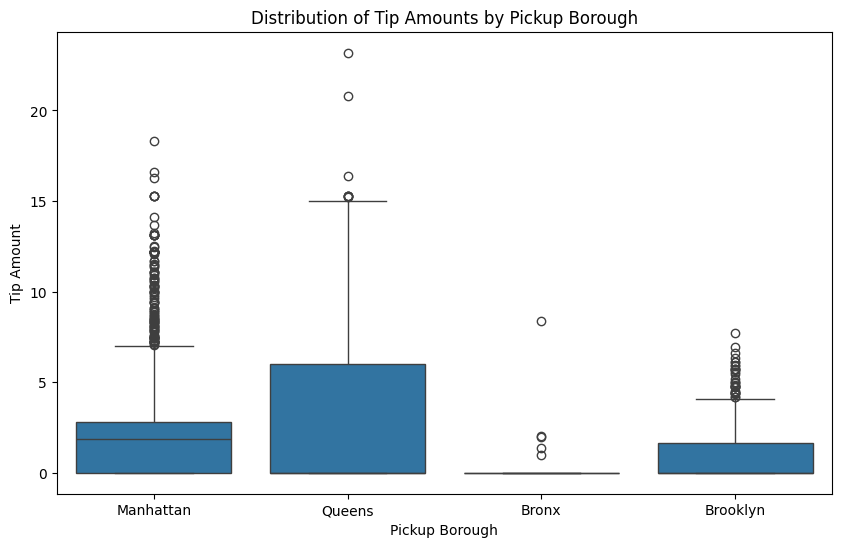

In [35]:
# Box Plot
# Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
# Use pickup_borough as the categorical axis and tip as the numeric axis.
plt.figure(figsize=(10, 6))
sns.boxplot(x='pickup_borough', y='tip', data=df)
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.title('Distribution of Tip Amounts by Pickup Borough')

Box Plot: Show spread and detect outliers.


## **Visualizations using Seaborn:**

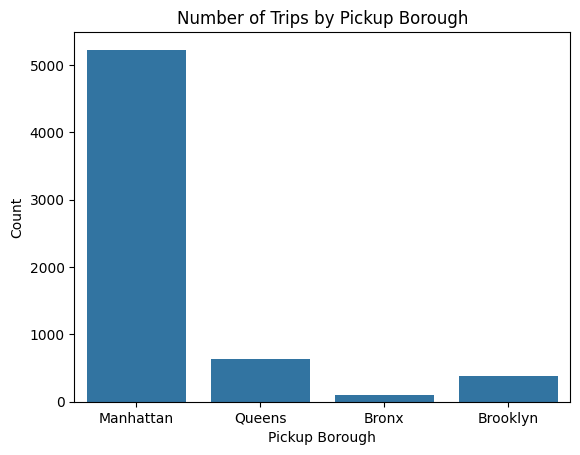

In [36]:

# Count Plot
# Create a count plot to visualize the number of trips in each pickup_borough.
# The x-axis should represent the boroughs, and the y-axis should show the count of trips.
sns.countplot(x='pickup_borough', data=df)
plt.xlabel('Pickup Borough')
plt.ylabel('Count')
plt.title('Number of Trips by Pickup Borough')
plt.show()

Count Plot: Show frequency of categories.

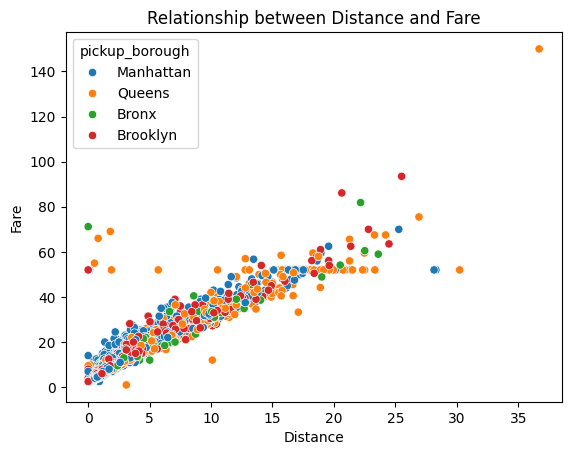

In [37]:
# Scatter Plot
# Plot a scatter plot to show the relationship between distance and fare.
# Use distance on the x-axis and fare on the y-axis to visualize any correlation.
# Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df)
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.title('Relationship between Distance and Fare')
plt.show()

Scatter Plot: Relationship between variables with styling.
* Each dot = one trip.
* Helps identify relationship between distance and fare.
* Colors represent boroughs.

<Axes: >

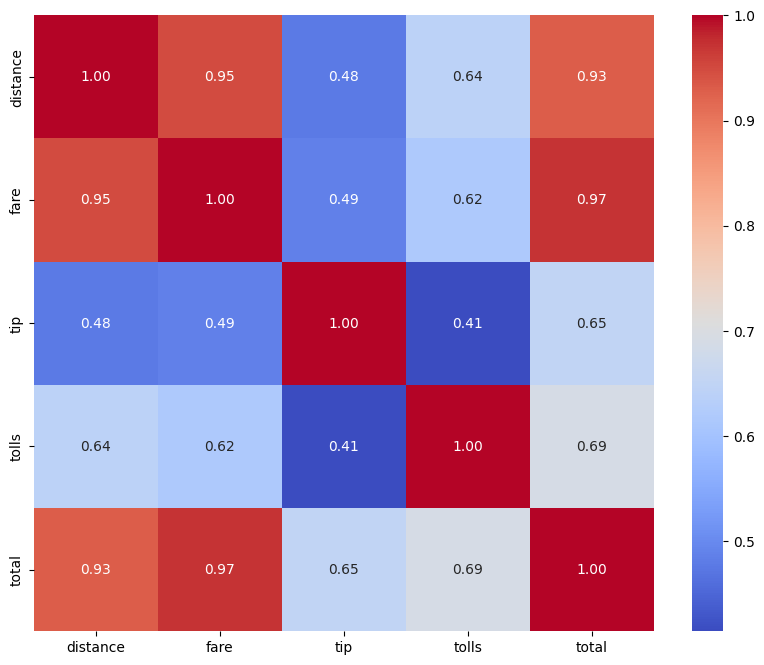

In [38]:
# Heatmap
# Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total.
# Use a correlation matrix to highlight the relationships.
correlation_matrix = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

Heatmap: Visualizes correlation or matrix data.

* Correlation Values:
      +1 → Strong positive relation,
       0 → No relation,
      -1 → Strong negative relation

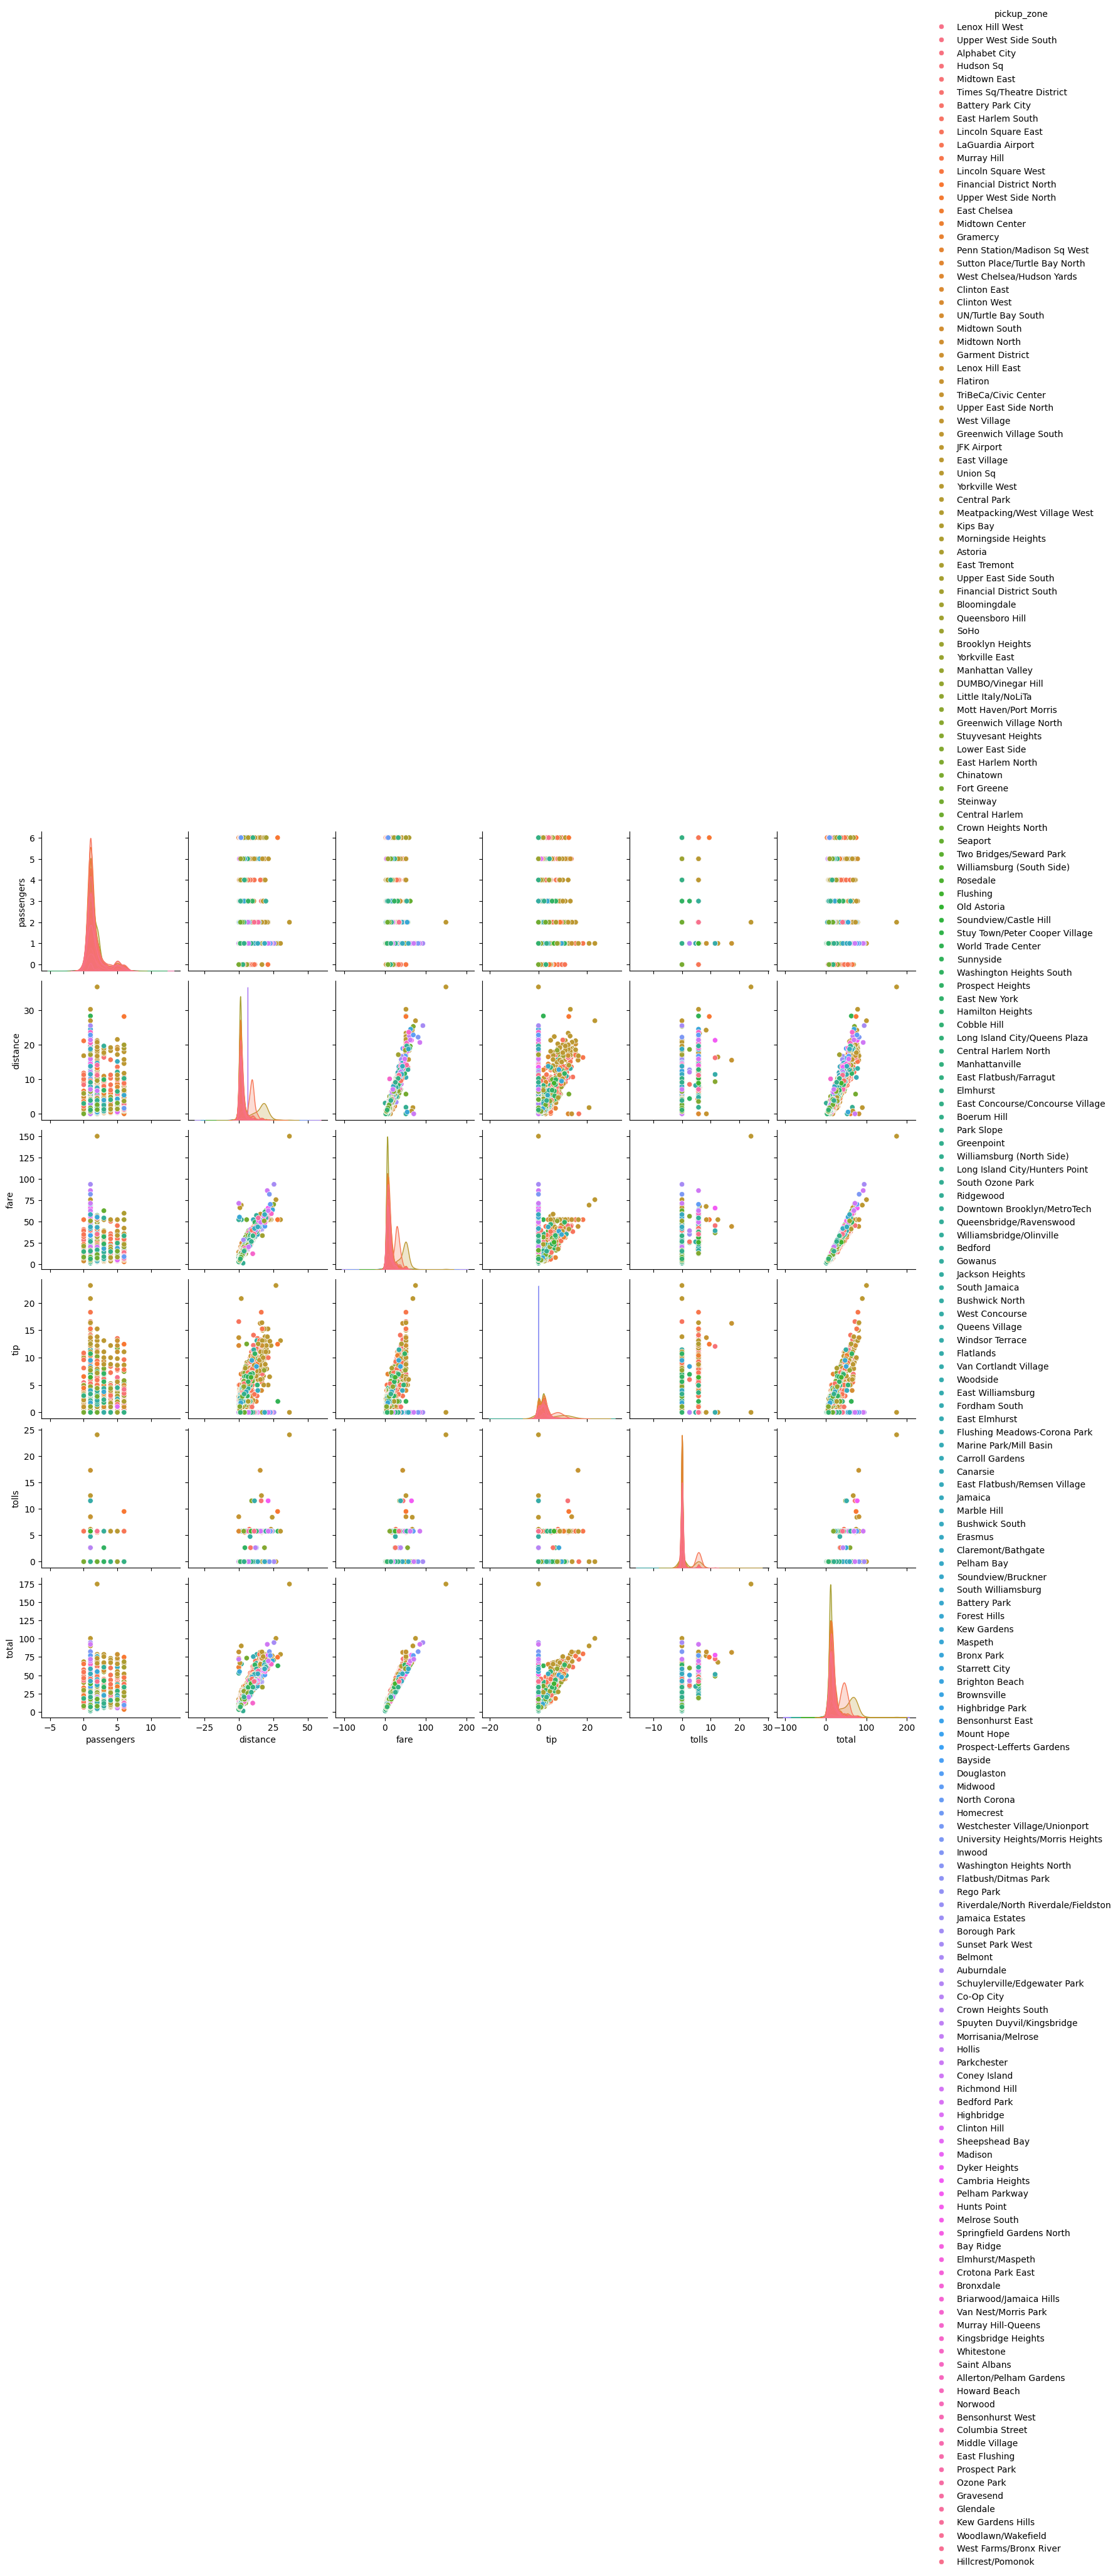

In [39]:
# Pair Plot
# Create a pair plot to visualize the pairwise relationships between distance, fare, tip and total.
# Color the data points according to the pickup_zone method to compare how different zones affect these variables.
sns.pairplot(df, hue='pickup_zone')
plt.show()

Pair Plot: Pairwise relationships across variables.
* Scatter plots between all variable pairs.
* Distribution on diagonals.
* Different colors for pickup zones.

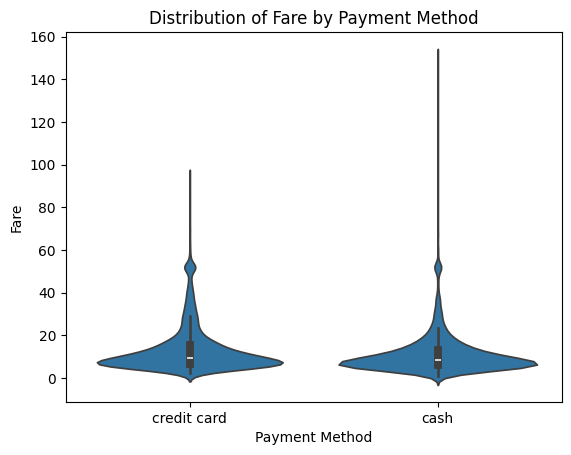

In [40]:
# Violin Plot
# Plot a violin plot to show the distribution of fare for each payment method.
# Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.
sns.violinplot(x='payment', y='fare', data=df)
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.title('Distribution of Fare by Payment Method')
plt.show()

Violin Plot: Combines box plot + density plot.

# **Conclusion** :

The taxi dataset was cleaned and analyzed using Pandas, Matplotlib, and Seaborn. Various visualizations helped identify patterns in fares, distances, payment methods, and trip distributions. Overall, the analysis provided useful insights and demonstrated the importance of data visualization in understanding real-world datasets.

